# Experiment 7: Text Classification Using Deep Learning Models

**Course:** Natural Language Processing  
**Experiment:** Sentiment analysis on the IMDB Movie Reviews Dataset

## Objectives

1. Implement sentiment classification using **Logistic Regression**.
2. Implement a sequence-based **LSTM** classifier.
3. Implement a **Vanilla Transformer Encoder** classifier from scratch.
4. Fine-tune a pretrained **BERT** model for sentiment classification.
5. Compare the models using **Precision, Recall, F1-score**, and **Confusion Matrices**.

**Dataset specified in the experiment sheet:** IMDB Dataset of 50K Movie Reviews (review text and sentiment label).

## 1. Environment Setup

Install the libraries required for classical machine learning, deep learning, plotting, and pretrained BERT. If a package is already installed, pip will generally leave it unchanged.

In [1]:
import sys
import subprocess
import importlib.util

packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "torch": "torch",
    "transformers": "transformers",
    "tqdm": "tqdm"
}

for module, package in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

print("Dependency setup complete.")

Dependency setup complete.


In [2]:
import os
import re
import copy
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Execution device:", DEVICE)

PyTorch version: 2.11.0+cu130
Execution device: cuda


## 2. Load the IMDB Dataset

### Dataset source

The experiment sheet points to the Kaggle **IMDB Dataset of 50K Movie Reviews**. Download the CSV from:

- Kaggle: https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
- Sample-code repository listed in the experiment sheet: https://github.com/Ankit152/IMDB-sentiment-analysis/tree/master

The expected CSV filename is `IMDB Dataset.csv`, with columns `review` and `sentiment`. This cell checks the current folder first, then offers a file-upload prompt in Google Colab.

In [3]:
from pathlib import Path

DATA_PATH = Path("IMDB Dataset.csv")

if not DATA_PATH.exists():
    # Colab upload fallback. On a local Jupyter installation, place the CSV
    # in the same directory as this notebook and rerun this cell.
    try:
        from google.colab import files
        print("Upload the IMDB Dataset.csv file.")
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if csv_names:
            DATA_PATH = Path(csv_names[0])
    except ImportError:
        print("Google Colab upload is unavailable. Place 'IMDB Dataset.csv' beside this notebook.")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Download 'IMDB Dataset.csv' from the Kaggle link in the experiment sheet "
        "and place it in the notebook directory."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Upload the IMDB Dataset.csv file.


Saving IMDB-Dataset.csv to IMDB-Dataset.csv
Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Columns: ['review', 'sentiment']


### 2.1 Inspect and clean the data

The dataset should contain review text and binary sentiment labels (`positive` or `negative`). We remove missing rows and duplicate reviews, normalize label text, and encode negative as `0` and positive as `1`.

In [4]:
required_columns = {"review", "sentiment"}
if not required_columns.issubset(set(df.columns)):
    raise ValueError(
        f"Expected columns {required_columns}, but found {set(df.columns)}"
    )

df = df[["review", "sentiment"]].dropna().drop_duplicates().copy()
df["review"] = df["review"].astype(str)
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()

label_map = {"negative": 0, "positive": 1}
unexpected = set(df["sentiment"].unique()) - set(label_map)
if unexpected:
    raise ValueError(f"Unexpected sentiment labels: {unexpected}")

df["label"] = df["sentiment"].map(label_map).astype(int)
df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nClass distribution:")
display(df["sentiment"].value_counts().to_frame("count"))
print("\nMissing values:")
display(df.isnull().sum().to_frame("missing values"))

Cleaned dataset shape: (49582, 3)

Class distribution:


,count
sentiment,
positive,24884
negative,24698



Missing values:


,missing values
review,0
sentiment,0
label,0


### 2.2 Visualize the class distribution

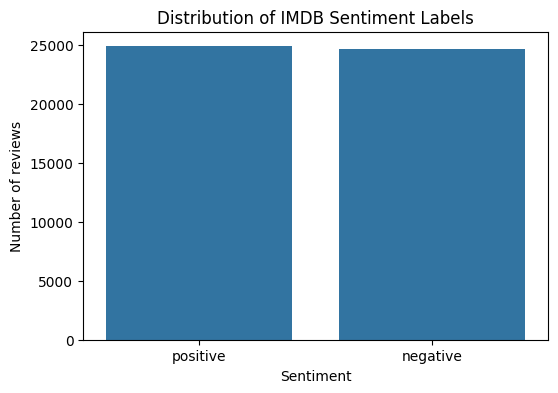

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sentiment")
plt.title("Distribution of IMDB Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.show()

## 3. Train-Test Split

Use a stratified split so that the positive/negative class proportions are preserved in both sets. A validation set is also created for selecting neural-network checkpoints.

In [6]:
X = df["review"].values
y = df["label"].values

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10,
    random_state=SEED, stratify=y_train_full
)

print(f"Training samples:   {len(X_train):,}")
print(f"Validation samples: {len(X_val):,}")
print(f"Testing samples:    {len(X_test):,}")

Training samples:   35,698
Validation samples: 3,967
Testing samples:    9,917


### 3.1 Optional training-size controls

The full dataset contains approximately 50,000 reviews. Logistic Regression can generally use the full training split. Neural models and BERT can take considerably longer, especially on CPU. The following settings cap neural-model training data while retaining the full held-out test set.

Increase `NEURAL_TRAIN_LIMIT` or set it to `None` to use all training examples. For a first run on limited hardware, start with 5,000–10,000 examples.

In [7]:
NEURAL_TRAIN_LIMIT = 10000   # Set to None to use the complete training split
MAX_VOCAB_SIZE = 30000
MAX_SEQ_LEN = 200
BATCH_SIZE = 64
NEURAL_EPOCHS = 3
LEARNING_RATE = 1e-3

def stratified_cap(texts, labels, limit, seed=SEED):
    if limit is None or limit >= len(texts):
        return np.asarray(texts), np.asarray(labels)
    x_keep, _, y_keep, _ = train_test_split(
        texts, labels, train_size=limit, random_state=seed, stratify=labels
    )
    return np.asarray(x_keep), np.asarray(y_keep)

X_nn_train, y_nn_train = stratified_cap(
    X_train, y_train, NEURAL_TRAIN_LIMIT
)
print("Neural training subset:", len(X_nn_train))

Neural training subset: 10000


## 4. Model 1 — Logistic Regression

Logistic Regression is the classical machine-learning baseline. Reviews are converted into TF-IDF feature vectors, and a Logistic Regression classifier predicts the sentiment label.

### 4.1 TF-IDF feature extraction

In [8]:
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    stop_words="english",
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF training matrix:", X_train_tfidf.shape)

TF-IDF training matrix: (35698, 50000)


### 4.2 Train Logistic Regression

In [9]:
logreg = LogisticRegression(
    max_iter=1000,
    C=2.0,
    solver="liblinear",
    random_state=SEED
)
logreg.fit(X_train_tfidf, y_train)

lr_val_pred = logreg.predict(X_val_tfidf)
print(classification_report(
    y_val, lr_val_pred, target_names=["negative", "positive"]
))

              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      1976
    positive       0.88      0.91      0.90      1991

    accuracy                           0.89      3967
   macro avg       0.89      0.89      0.89      3967
weighted avg       0.89      0.89      0.89      3967



## 5. Prepare Text for Neural Models

The LSTM and Vanilla Transformer use integer token IDs rather than TF-IDF vectors. We build a vocabulary from the neural training split only. Special tokens are `<pad>` (0) and `<unk>` (1).

In [10]:
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"

def basic_tokenize(text):
    return re.findall(r"[a-z0-9']+", str(text).lower())

token_counts = Counter()
for review in tqdm(X_nn_train, desc="Building vocabulary"):
    token_counts.update(basic_tokenize(review))

vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for token, count in token_counts.most_common(MAX_VOCAB_SIZE - 2):
    vocab[token] = len(vocab)

print("Vocabulary size:", len(vocab))

def encode_review(text, max_len=MAX_SEQ_LEN):
    ids = [vocab.get(token, vocab[UNK_TOKEN]) for token in basic_tokenize(text)]
    ids = ids[:max_len]
    if not ids:
        ids = [vocab[UNK_TOKEN]]
    return ids

class ReviewDataset(Dataset):
    def __init__(self, texts, labels, max_len=MAX_SEQ_LEN):
        self.texts = list(texts)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        ids = encode_review(self.texts[index], self.max_len)
        return torch.tensor(ids, dtype=torch.long), torch.tensor(self.labels[index], dtype=torch.long)

def collate_reviews(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    padded = nn.utils.rnn.pad_sequence(
        sequences, batch_first=True, padding_value=vocab[PAD_TOKEN]
    )
    return padded, lengths, torch.stack(labels)

train_dataset = ReviewDataset(X_nn_train, y_nn_train)
val_dataset = ReviewDataset(X_val, y_val)
test_dataset = ReviewDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_reviews
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_reviews
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_reviews
)

print("Neural data loaders ready.")

Building vocabulary:   0%|          | 0/10000 [00:00<?, ?it/s]

Vocabulary size: 30000
Neural data loaders ready.


## 6. Shared Training and Evaluation Utilities

The neural models use cross-entropy loss and Adam optimization. Validation F1 is monitored and the best-performing model checkpoint is retained.

In [11]:
def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

def train_torch_model(model, train_loader, val_loader, epochs=NEURAL_EPOCHS, lr=LEARNING_RATE):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    best_f1 = -1
    best_state = copy.deepcopy(model.state_dict())
    history = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for input_ids, lengths, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
            input_ids = input_ids.to(DEVICE)
            lengths = lengths.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()
            logits = model(input_ids, lengths)
            loss = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += loss.item()

        val_true, val_pred = predict_torch_model(model, val_loader)
        metrics = calculate_metrics(val_true, val_pred)
        avg_loss = running_loss / max(len(train_loader), 1)
        history.append({"epoch": epoch + 1, "loss": avg_loss, **metrics})

        print(
            f"Epoch {epoch+1}: loss={avg_loss:.4f}, "
            f"val_precision={metrics['Precision']:.4f}, "
            f"val_recall={metrics['Recall']:.4f}, "
            f"val_f1={metrics['F1-score']:.4f}"
        )

        if metrics["F1-score"] > best_f1:
            best_f1 = metrics["F1-score"]
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

@torch.no_grad()
def predict_torch_model(model, loader):
    model.eval()
    all_true, all_pred = [], []
    for input_ids, lengths, labels in loader:
        input_ids = input_ids.to(DEVICE)
        lengths = lengths.to(DEVICE)
        logits = model(input_ids, lengths)
        predictions = torch.argmax(logits, dim=1).cpu().numpy()
        all_pred.extend(predictions)
        all_true.extend(labels.numpy())
    return np.asarray(all_true), np.asarray(all_pred)

def plot_training_history(history, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history["epoch"], history["loss"], marker="o", label="Training loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.show()

## 7. Model 2 — LSTM Sentiment Classifier

An LSTM (Long Short-Term Memory) network processes the review token sequence and maintains a hidden state that captures contextual information. The final hidden representation is passed to a fully connected classification layer.

Epoch 1/3:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 1: loss=0.6631, val_precision=0.7574, val_recall=0.3998, val_f1=0.5233


Epoch 2/3:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 2: loss=0.5139, val_precision=0.7312, val_recall=0.7951, val_f1=0.7618


Epoch 3/3:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 3: loss=0.3744, val_precision=0.7366, val_recall=0.8076, val_f1=0.7705


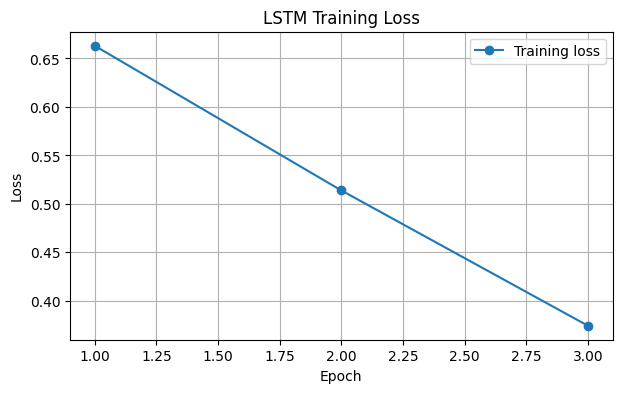

In [12]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, num_layers=1, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=vocab[PAD_TOKEN])
        self.lstm = nn.LSTM(
            embedding_dim, hidden_dim, num_layers=num_layers,
            batch_first=True, bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, 2)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        # Concatenate final forward and backward hidden states.
        representation = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(representation))

lstm_model = LSTMClassifier(len(vocab))
lstm_model, lstm_history = train_torch_model(
    lstm_model, train_loader, val_loader,
    epochs=NEURAL_EPOCHS, lr=LEARNING_RATE
)
plot_training_history(lstm_history, "LSTM Training Loss")

### 7.1 Evaluate LSTM

In [13]:
lstm_y_true, lstm_y_pred = predict_torch_model(lstm_model, test_loader)
lstm_metrics = calculate_metrics(lstm_y_true, lstm_y_pred)
print("LSTM Test Metrics:", lstm_metrics)
print(classification_report(
    lstm_y_true, lstm_y_pred, target_names=["negative", "positive"]
))

LSTM Test Metrics: {'Accuracy': 0.7682766965816276, 'Precision': 0.7487465181058496, 'Recall': 0.810126582278481, 'F1-score': 0.7782281412854661}
              precision    recall  f1-score   support

    negative       0.79      0.73      0.76      4940
    positive       0.75      0.81      0.78      4977

    accuracy                           0.77      9917
   macro avg       0.77      0.77      0.77      9917
weighted avg       0.77      0.77      0.77      9917



## 8. Model 3 — Vanilla Transformer Encoder

This model implements a Transformer encoder from scratch using:
- Token embeddings and positional embeddings.
- Multi-head self-attention.
- Feed-forward layers.
- Residual connections and layer normalization.
- Masking for padding tokens.
- Mean pooling over non-padding token representations for classification.

Unlike BERT, this is a small Transformer trained from scratch on the IMDB training split.

Epoch 1/3:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 1: loss=0.5793, val_precision=0.7590, val_recall=0.7750, val_f1=0.7669


Epoch 2/3:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 2: loss=0.3873, val_precision=0.8244, val_recall=0.7760, val_f1=0.7995


Epoch 3/3:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 3: loss=0.2541, val_precision=0.7458, val_recall=0.8960, val_f1=0.8141


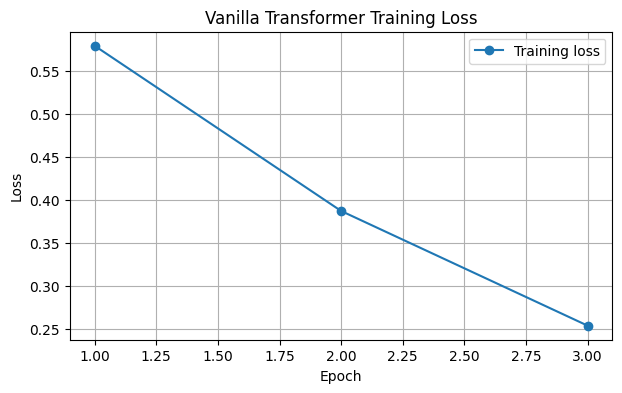

In [14]:
class TransformerClassifier(nn.Module):
    def __init__(
        self, vocab_size, max_len=MAX_SEQ_LEN, embedding_dim=128,
        num_heads=4, num_layers=2, ff_dim=256, dropout=0.2
    ):
        super().__init__()
        self.token_embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=vocab[PAD_TOKEN]
        )
        self.position_embedding = nn.Embedding(max_len, embedding_dim)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(embedding_dim, 2)
        self.max_len = max_len

    def forward(self, input_ids, lengths):
        batch_size, seq_len = input_ids.shape
        positions = torch.arange(seq_len, device=input_ids.device).unsqueeze(0).expand(batch_size, -1)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)

        padding_mask = input_ids.eq(vocab[PAD_TOKEN])
        encoded = self.encoder(x, src_key_padding_mask=padding_mask)

        valid_mask = (~padding_mask).unsqueeze(-1).float()
        pooled = (encoded * valid_mask).sum(dim=1) / valid_mask.sum(dim=1).clamp(min=1.0)
        return self.classifier(self.dropout(pooled))

transformer_model = TransformerClassifier(len(vocab))
transformer_model, transformer_history = train_torch_model(
    transformer_model, train_loader, val_loader,
    epochs=NEURAL_EPOCHS, lr=LEARNING_RATE
)
plot_training_history(transformer_history, "Vanilla Transformer Training Loss")

### 8.1 Evaluate Vanilla Transformer

In [15]:
transformer_y_true, transformer_y_pred = predict_torch_model(
    transformer_model, test_loader
)
transformer_metrics = calculate_metrics(transformer_y_true, transformer_y_pred)
print("Vanilla Transformer Test Metrics:", transformer_metrics)
print(classification_report(
    transformer_y_true, transformer_y_pred,
    target_names=["negative", "positive"]
))

Vanilla Transformer Test Metrics: {'Accuracy': 0.8025612584450943, 'Precision': 0.7510394146016963, 'Recall': 0.9073739200321479, 'F1-score': 0.8218380345768881}
              precision    recall  f1-score   support

    negative       0.88      0.70      0.78      4940
    positive       0.75      0.91      0.82      4977

    accuracy                           0.80      9917
   macro avg       0.82      0.80      0.80      9917
weighted avg       0.82      0.80      0.80      9917



## 9. Model 4 — Pretrained BERT

BERT (Bidirectional Encoder Representations from Transformers) is a pretrained bidirectional Transformer language model. We fine-tune `bert-base-uncased` with a two-class sentiment classification head.

**Requirements:** This section downloads pretrained model weights and tokenizer files from Hugging Face. Internet access is required the first time. A GPU is strongly recommended. If running on CPU, reduce the training subset and number of epochs.

In [16]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import Dataset, DataLoader

BERT_MODEL_NAME = "bert-base-uncased"
BERT_MAX_LEN = 256
BERT_BATCH_SIZE = 8 if DEVICE.type == "cpu" else 16
BERT_EPOCHS = 2
BERT_TRAIN_LIMIT = 5000  # Set to None to use all training examples

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME, num_labels=2
).to(DEVICE)

X_bert_train, y_bert_train = stratified_cap(
    X_train, y_train, BERT_TRAIN_LIMIT
)
print("BERT training samples:", len(X_bert_train))
print("BERT device:", DEVICE)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT training samples: 5000
BERT device: cuda


### 9.1 Tokenize and create BERT data loaders

In [17]:
class BertReviewDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=BERT_MAX_LEN):
        self.encodings = tokenizer(
            list(texts),
            truncation=True,
            padding="max_length",
            max_length=max_len,
            return_tensors="pt"
        )
        self.labels = torch.tensor(np.asarray(labels), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: value[idx] for key, value in self.encodings.items()}
        item["labels"] = self.labels[idx]
        return item

bert_train_dataset = BertReviewDataset(
    X_bert_train, y_bert_train, bert_tokenizer
)
bert_val_dataset = BertReviewDataset(X_val, y_val, bert_tokenizer)
bert_test_dataset = BertReviewDataset(X_test, y_test, bert_tokenizer)

bert_train_loader = DataLoader(
    bert_train_dataset, batch_size=BERT_BATCH_SIZE, shuffle=True
)
bert_val_loader = DataLoader(
    bert_val_dataset, batch_size=BERT_BATCH_SIZE
)
bert_test_loader = DataLoader(
    bert_test_dataset, batch_size=BERT_BATCH_SIZE
)

print("BERT data loaders ready.")

BERT data loaders ready.


### 9.2 Fine-tune BERT

The best checkpoint is selected using validation F1-score. Mixed precision is enabled on CUDA to reduce memory use where supported.

BERT Epoch 1/2:   0%|          | 0/313 [00:00<?, ?it/s]

Epoch 1: loss=0.3536, val_precision=0.8940, val_recall=0.8940, val_f1=0.8940


BERT Epoch 2/2:   0%|          | 0/313 [00:00<?, ?it/s]

Epoch 2: loss=0.1908, val_precision=0.9207, val_recall=0.8227, val_f1=0.8690


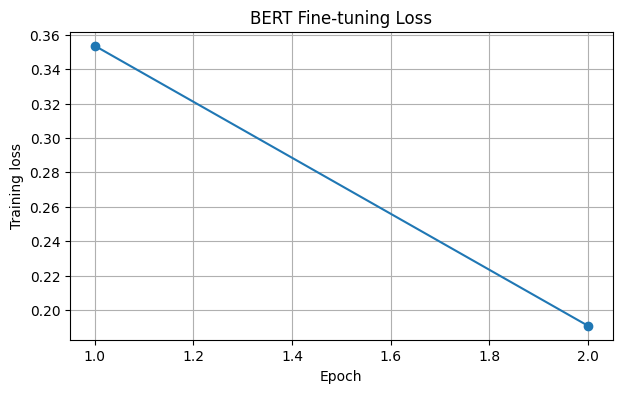

In [18]:
def evaluate_bert(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            labels = batch.pop("labels")
            outputs = model(**batch)
            preds = torch.argmax(outputs.logits, dim=1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
    return np.asarray(y_true), np.asarray(y_pred)

bert_optimizer = torch.optim.AdamW(bert_model.parameters(), lr=2e-5)
bert_history = []
best_bert_f1 = -1
best_bert_state = copy.deepcopy(bert_model.state_dict())
scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

for epoch in range(BERT_EPOCHS):
    bert_model.train()
    total_loss = 0.0

    for batch in tqdm(bert_train_loader, desc=f"BERT Epoch {epoch+1}/{BERT_EPOCHS}"):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        bert_optimizer.zero_grad()

        with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
            outputs = bert_model(**batch)
            loss = outputs.loss

        scaler.scale(loss).backward()
        scaler.unscale_(bert_optimizer)
        nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
        scaler.step(bert_optimizer)
        scaler.update()
        total_loss += loss.item()

    val_true, val_pred = evaluate_bert(bert_model, bert_val_loader)
    val_metrics = calculate_metrics(val_true, val_pred)
    avg_loss = total_loss / max(len(bert_train_loader), 1)
    bert_history.append({"epoch": epoch + 1, "loss": avg_loss, **val_metrics})

    print(
        f"Epoch {epoch+1}: loss={avg_loss:.4f}, "
        f"val_precision={val_metrics['Precision']:.4f}, "
        f"val_recall={val_metrics['Recall']:.4f}, "
        f"val_f1={val_metrics['F1-score']:.4f}"
    )

    if val_metrics["F1-score"] > best_bert_f1:
        best_bert_f1 = val_metrics["F1-score"]
        best_bert_state = copy.deepcopy(bert_model.state_dict())

bert_model.load_state_dict(best_bert_state)
bert_history = pd.DataFrame(bert_history)

plt.figure(figsize=(7, 4))
plt.plot(bert_history["epoch"], bert_history["loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("BERT Fine-tuning Loss")
plt.grid(True)
plt.show()

### 9.3 Evaluate BERT

In [19]:
bert_y_true, bert_y_pred = evaluate_bert(bert_model, bert_test_loader)
bert_metrics = calculate_metrics(bert_y_true, bert_y_pred)

print("BERT Test Metrics:", bert_metrics)
print(classification_report(
    bert_y_true, bert_y_pred, target_names=["negative", "positive"]
))

BERT Test Metrics: {'Accuracy': 0.8991630533427448, 'Precision': 0.8982575605848188, 'Recall': 0.9011452682338759, 'F1-score': 0.8996990972918756}
              precision    recall  f1-score   support

    negative       0.90      0.90      0.90      4940
    positive       0.90      0.90      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



## 10. Comparative Evaluation

Evaluate every model on the same held-out test set. Precision, Recall, and F1-score are calculated with the positive class as the positive label. Logistic Regression and the neural models use the full test split; neural models are trained on the configured subset.

In [20]:
# Logistic Regression test predictions
lr_y_pred = logreg.predict(X_test_tfidf)
lr_metrics = calculate_metrics(y_test, lr_y_pred)

results = {
    "Logistic Regression": lr_metrics,
    "LSTM": lstm_metrics,
    "Vanilla Transformer": transformer_metrics,
    "BERT (bert-base-uncased)": bert_metrics
}

results_df = pd.DataFrame(results).T
display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.9015,0.8926,0.9136,0.9030
LSTM,0.7683,0.7487,0.8101,0.7782
Vanilla Transformer,0.8026,0.7510,0.9074,0.8218
BERT (bert-base-uncased),0.8992,0.8983,0.9011,0.8997


### 10.1 Compare F1-score, Precision, and Recall

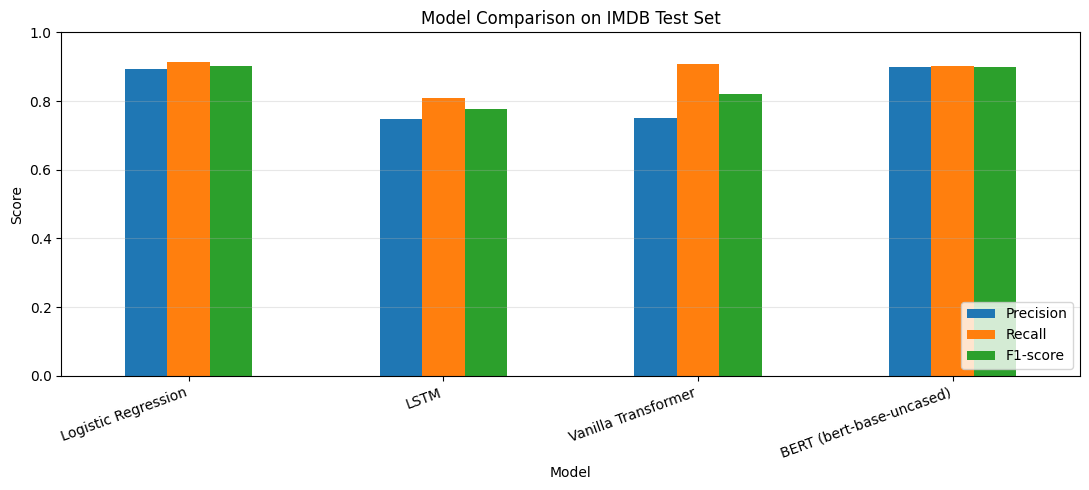

In [21]:
metrics_to_plot = ["Precision", "Recall", "F1-score"]
results_df[metrics_to_plot].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1),
    title="Model Comparison on IMDB Test Set"
)
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 11. Confusion Matrix Analysis

A confusion matrix displays true negatives, false positives, false negatives, and true positives. Rows represent actual labels and columns represent predicted labels.

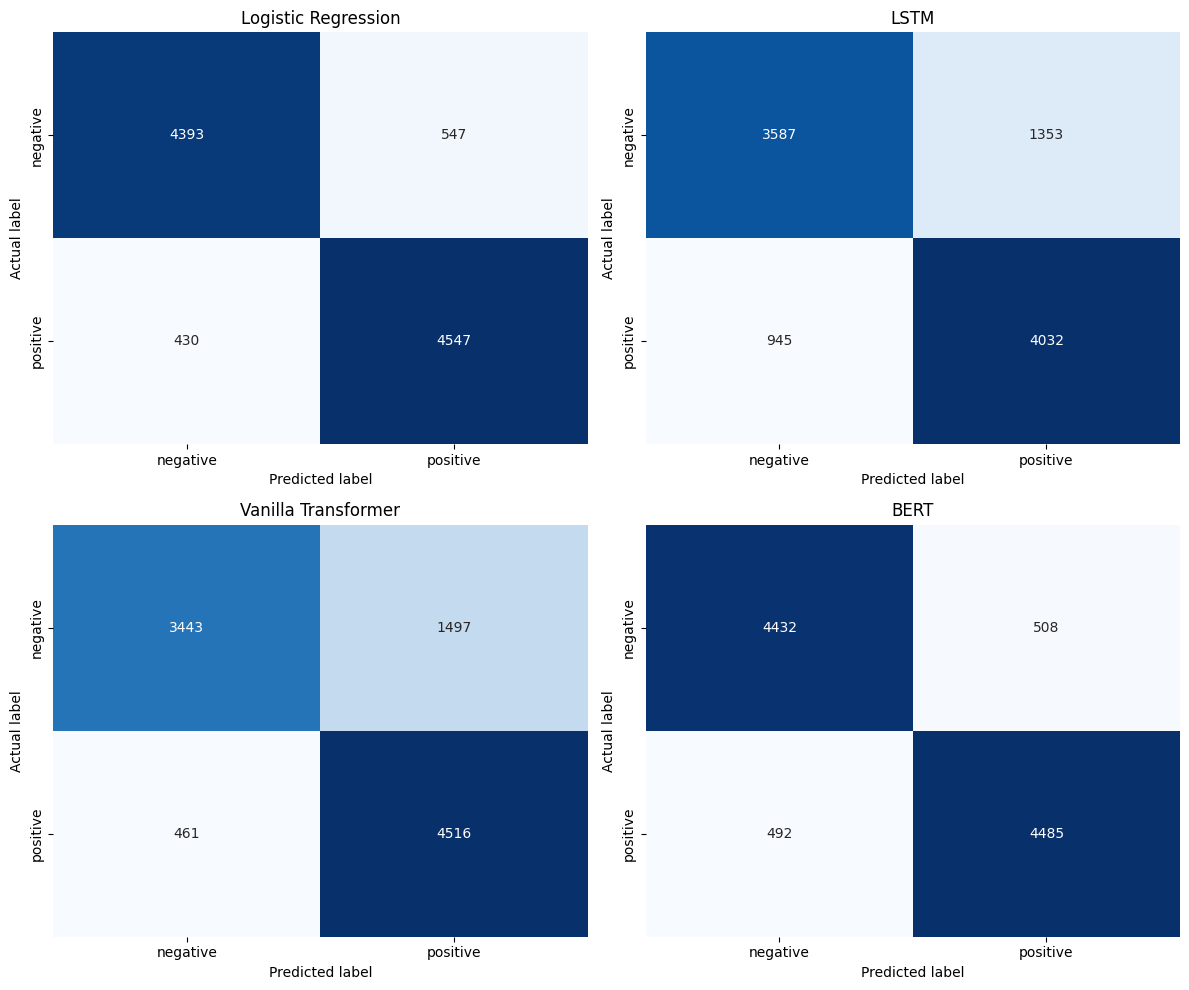

In [22]:
all_predictions = {
    "Logistic Regression": (y_test, lr_y_pred),
    "LSTM": (lstm_y_true, lstm_y_pred),
    "Vanilla Transformer": (transformer_y_true, transformer_y_pred),
    "BERT": (bert_y_true, bert_y_pred)
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (model_name, (true_labels, predicted_labels)) in zip(
    axes.flatten(), all_predictions.items()
):
    cm = confusion_matrix(true_labels, predicted_labels, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["negative", "positive"],
        yticklabels=["negative", "positive"]
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()

### 11.1 Classification reports

In [23]:
for model_name, (true_labels, predicted_labels) in all_predictions.items():
    print("=" * 70)
    print(model_name)
    print(classification_report(
        true_labels, predicted_labels,
        labels=[0, 1], target_names=["negative", "positive"],
        zero_division=0
    ))

Logistic Regression
              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      4940
    positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917

LSTM
              precision    recall  f1-score   support

    negative       0.79      0.73      0.76      4940
    positive       0.75      0.81      0.78      4977

    accuracy                           0.77      9917
   macro avg       0.77      0.77      0.77      9917
weighted avg       0.77      0.77      0.77      9917

Vanilla Transformer
              precision    recall  f1-score   support

    negative       0.88      0.70      0.78      4940
    positive       0.75      0.91      0.82      4977

    accuracy                           0.80      9917
   macro avg       0.82      0.80      0.80      9917
weighted avg       0.82      

## 12. Test the Models on Custom Movie Reviews

Enter any movie review below. The notebook predicts whether the sentiment is positive or negative using each trained model.

In [24]:
def predict_custom_review(review_text):
    # Logistic Regression
    lr_vector = tfidf.transform([review_text])
    lr_pred = int(logreg.predict(lr_vector)[0])

    # LSTM
    lstm_ids = encode_review(review_text)
    lstm_input = torch.tensor([lstm_ids], dtype=torch.long).to(DEVICE)
    lstm_lengths = torch.tensor([len(lstm_ids)], dtype=torch.long).to(DEVICE)
    lstm_model.eval()
    with torch.no_grad():
        lstm_pred = int(torch.argmax(lstm_model(lstm_input, lstm_lengths), dim=1).item())

    # Vanilla Transformer
    transformer_model.eval()
    with torch.no_grad():
        transformer_pred = int(torch.argmax(
            transformer_model(lstm_input, lstm_lengths), dim=1
        ).item())

    # BERT
    encoded = bert_tokenizer(
        review_text, return_tensors="pt", truncation=True,
        padding="max_length", max_length=BERT_MAX_LEN
    )
    encoded = {k: v.to(DEVICE) for k, v in encoded.items()}
    bert_model.eval()
    with torch.no_grad():
        bert_pred = int(torch.argmax(bert_model(**encoded).logits, dim=1).item())

    label_names = {0: "Negative", 1: "Positive"}
    return pd.DataFrame({
        "Model": ["Logistic Regression", "LSTM", "Vanilla Transformer", "BERT"],
        "Predicted sentiment": [
            label_names[lr_pred], label_names[lstm_pred],
            label_names[transformer_pred], label_names[bert_pred]
        ]
    })

sample_review = "The movie was beautifully directed and the performances were excellent."
display(predict_custom_review(sample_review))

,Model,Predicted sentiment
0,Logistic Regression,Positive
1,LSTM,Positive
2,Vanilla Transformer,Positive
3,BERT,Positive


## 13. Results

Sentiment analysis on the IMDB Movie Reviews Dataset was implemented using Logistic Regression, LSTM, a Vanilla Transformer Encoder, and pretrained BERT. The models were evaluated using Precision, Recall, F1-score, classification reports, and confusion matrices. The comparative results are presented in the generated metric table and plots.

## 14. Conclusion

This experiment demonstrates classical and deep-learning approaches to binary sentiment classification. Logistic Regression uses TF-IDF features, LSTM learns sequential representations, the Vanilla Transformer applies self-attention without pretrained weights, and BERT fine-tuning adapts a pretrained bidirectional language model to sentiment classification.

The evaluation metrics and confusion matrices provide a quantitative comparison of the four approaches. The final conclusion about the best-performing model should be based on the measured test-set results from the notebook run.

## 15. References

1. Experiment 7 handout: *Text Classification using Deep Learning Models*.
2. Kaggle — IMDB Dataset of 50K Movie Reviews: https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
3. Sample code repository specified in the handout: https://github.com/Ankit152/IMDB-sentiment-analysis/tree/master
4. scikit-learn documentation: https://scikit-learn.org/stable/
5. PyTorch documentation: https://pytorch.org/docs/stable/
6. Hugging Face Transformers documentation: https://huggingface.co/docs/transformers/

---

**End of Experiment 7**